![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/visual-nlp-workshop/blob/master/jupyter/SparkOcrImageLogoDetection.ipynb)

# Example of usage Spark OCR for Logo Detection
This notebook shows how to detect logos in documents using the `ImageLogoDetector` pretrained model `logo_detector_v1`.

## Install spark-ocr python packge
Need to specify:
- secret
- license
- aws credentials

In [3]:
secret = ""
license = ""
AWS_ACCESS_KEY_ID = ""
AWS_SECRET_ACCESS_KEY = ""

version = secret.split("-")[0]
spark_ocr_jar_path = "../../target/scala-2.12"
pdfPath = "./mixed_formats/report.pdf"

In [4]:
%%bash
if python -c 'import google.colab' &> /dev/null; then
    echo "Run on Google Colab!"
    echo "Install Open JDK"
    apt-get install -y openjdk-8-jdk-headless -qq > /dev/null
    java -version
fi

In [5]:
import os
import sys

if AWS_ACCESS_KEY_ID != "":
    os.environ["AWS_ACCESS_KEY_ID"] = AWS_ACCESS_KEY_ID
    os.environ["AWS_SECRET_ACCESS_KEY"] = AWS_SECRET_ACCESS_KEY
    
if license:
    os.environ['JSL_OCR_LICENSE'] = license
    
if 'google.colab' in sys.modules:
  os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
  os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

In [6]:
# %pip install ../../python/dist/spark-ocr-7.0.1+spark30.tar.gz

In [7]:
# install from PYPI using secret
#%pip install spark-ocr==$version+spark30 --extra-index-url=https://pypi.johnsnowlabs.com/$secret --upgrade

## Initialization of spark session
Need specify path to `spark-ocr-assembly.jar` or `secret`

In [8]:
from pyspark import SparkConf
from sparkocr import start

spark = start(secret=secret, jar_path = spark_ocr_jar_path)

spark

Spark version: 3.5.1
Spark NLP version: 7.0.1
Spark NLP for Healthcare version: 7.0.0
Spark OCR version: 7.0.1



## Read PDF and display it

In [15]:
from pyspark.ml import PipelineModel
import pyspark.sql.functions as f
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import display_images

pdf_df = spark.read.format("binaryFile").load(pdfPath)

image_df = PdfToImage().setImageType(ImageType.TYPE_3BYTE_BGR).transform(pdf_df)
display_images(image_df, "image")

## Define OCR Pipeline

In [10]:
pdf_to_image = PdfToImage() \
    .setInputCol("content") \
    .setOutputCol("image") \
    .setImageType(ImageType.TYPE_3BYTE_BGR)

logo_detector = ImageLogoDetector \
    .pretrained("logo_detector_v1", "en", "clinical/ocr") \
    .setInputCol("image") \
    .setOutputCol("logo_regions")

draw_regions = ImageDrawRegions() \
   .setInputCol("image") \
   .setInputRegionsCol("logo_regions") \
   .setOutputCol("image_with_regions") \
   .setFontSize(16) \
   .setRectColor(Color.red)

pipeline = PipelineModel(stages=[
    pdf_to_image,
    logo_detector,
    draw_regions
])

logo_detector_v1 download started this may take some time.
Approximate size to download 31.6 MB


## Run pipeline and show results


    Image #0:
    Origin: file:/home/jose/spark-ocr/workshop/jupyter/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4254 px
    Height: 3770 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


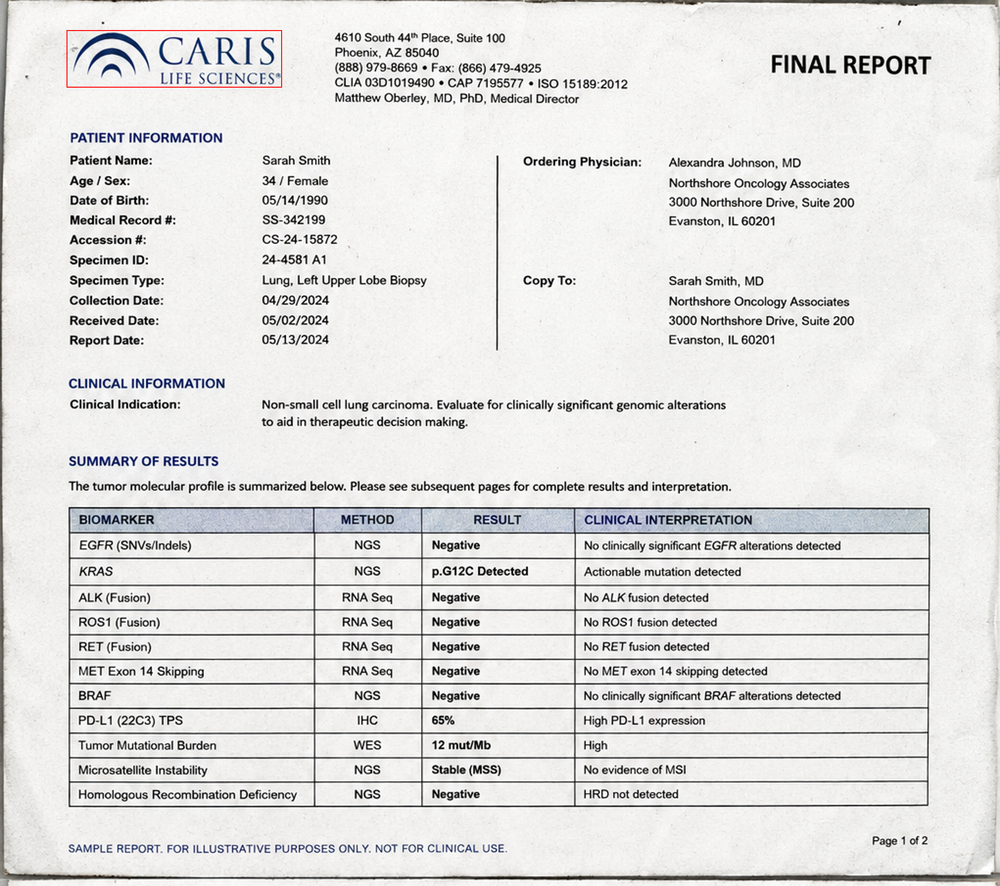


    Image #1:
    Origin: file:/home/jose/spark-ocr/workshop/jupyter/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4241 px
    Height: 2650 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


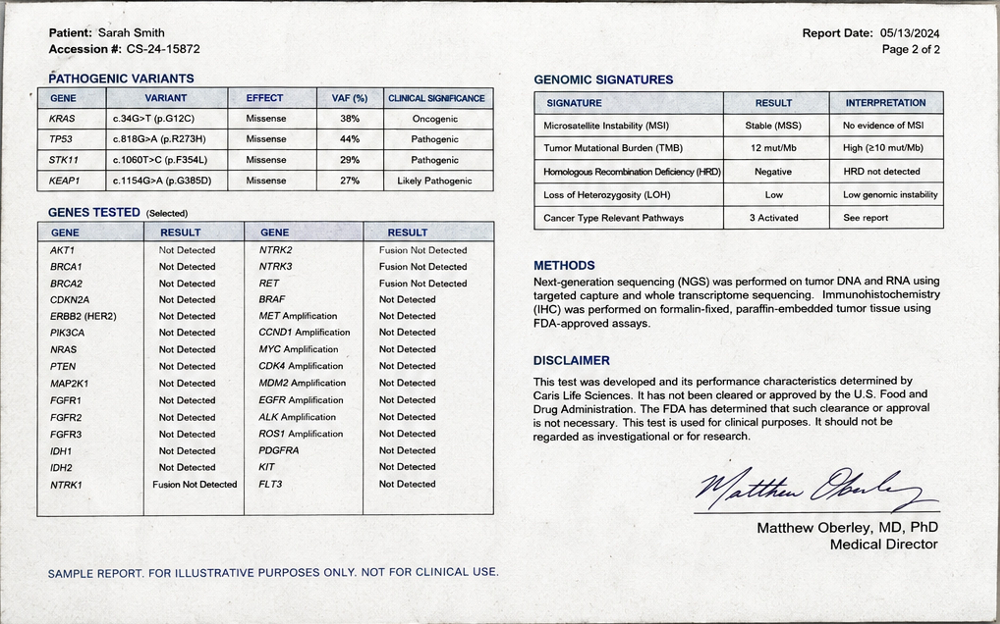

In [11]:
result = pipeline.transform(pdf_df).cache()
display_images(result, "image_with_regions")

### Output format for regions

In [12]:
result.select("logo_regions").printSchema()

root
 |-- logo_regions: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- index: integer (nullable = false)
 |    |    |-- page: integer (nullable = false)
 |    |    |-- x: float (nullable = false)
 |    |    |-- y: float (nullable = false)
 |    |    |-- width: float (nullable = false)
 |    |    |-- height: float (nullable = false)
 |    |    |-- score: float (nullable = false)
 |    |    |-- label: string (nullable = true)
 |    |    |-- angle: float (nullable = false)
 |    |    |-- rotated: boolean (nullable = false)



### Display coordinates and scores of regions

In [13]:
path_array = f.split(result["path"], "/")

result.withColumn("coordinate", f.explode_outer(result["logo_regions"])) \
    .withColumn("filename", path_array.getItem(f.size(path_array) - 1)) \
    .withColumn("has_logo", f.size(result["logo_regions"]) > 0) \
    .select("filename", "pagenum", "has_logo", "coordinate") \
    .show(truncate=False)

/home/jose/.local/lib/python3.10/site-packages/pyspark/sql/column.py:460: FutureWarning: A column as 'key' in getItem is deprecated as of Spark 3.0, and will not be supported in the future release. Use `column[key]` or `column.key` syntax instead.
  warnings.warn(


+----------+-------+--------+----------------------------------------------------------------+
|filename  |pagenum|has_logo|coordinate                                                      |
+----------+-------+--------+----------------------------------------------------------------+
|report.pdf|0      |true    |{0, 0, 285.0, 130.0, 913.0, 241.0, 0.87089545, logo, 0.0, false}|
|report.pdf|1      |false   |NULL                                                            |
+----------+-------+--------+----------------------------------------------------------------+



In [14]:
assert( result.count() > 0 )